In [34]:
!pip install torch torchvision matplotlib -q

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import copy
from sklearn.model_selection import StratifiedShuffleSplit


In [35]:
from google.colab import drive
import pandas as pd
from PIL import Image


drive.mount('/content/drive')

# -------------------------------------------
FOLDERNAME = 'computer vision project'
assert FOLDERNAME is not None, "[!] Enter the foldername."
FullPath = '/content/drive/MyDrive/' + FOLDERNAME
print(FullPath)

import os
os.chdir(FullPath)
!pwd # check that your folder is the current working directory

# Now that we've mounted your Drive, this ensures that
# the Python interpreter of the Colab VM can load
# python files from within it.
import sys
sys.path.append(FullPath)
import preprocessing as prep
# -------------------------------------------

dataset_path = Path('/content/drive/MyDrive/computer vision project/db_lisa_tiny')
annotations_file = dataset_path / 'annotations.csv'

print(f"Checking dataset path: {dataset_path}")
if not dataset_path.exists():
    raise FileNotFoundError(f"Dataset path not found: {dataset_path}")

print(f"Checking annotations file: {annotations_file}")
if not annotations_file.exists():
    raise FileNotFoundError(f"Annotations file not found: {annotations_file}")

annotations_df = pd.read_csv(annotations_file)
print(f"Loaded {len(annotations_df)} annotations")
display(annotations_df.head())

# False = full image baseline, True = bounding-box crop
use_bbox_crop = True

class CustomImageDataset(torch.utils.data.Dataset):
    def __init__(self, annotations_df, img_dir, transform=None, use_bbox_crop=False, pad_ratio=0.00):
        self.annotations = annotations_df.reset_index(drop=True)
        self.img_dir = Path(img_dir)
        self.transform = transform
        self.use_bbox_crop = use_bbox_crop
        self.pad_ratio = pad_ratio

        classes = sorted(self.annotations['class'].unique())
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
        self.idx_to_class = {i: cls_name for cls_name, i in self.class_to_idx.items()}

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, idx):
        row = self.annotations.iloc[idx]
        img_path = self.img_dir / row['filename']
        image = Image.open(img_path).convert('RGB')

        if self.use_bbox_crop:
          x1, y1, x2, y2 = map(int, [row['x1'], row['y1'], row['x2'], row['y2']])

          box_w = x2 - x1
          box_h = y2 - y1
          pad_x = int(box_w * self.pad_ratio)
          pad_y = int(box_h * self.pad_ratio)

          x1 = max(0, x1 - pad_x)
          y1 = max(0, y1 - pad_y)
          x2 = min(image.width, x2 + pad_x)
          y2 = min(image.height, y2 + pad_y)

          image = image.crop((x1, y1, x2, y2))

        # Apply augmentation
        #if self.transform:
        #  image = self.transform(image)

        # Convert PIL to NumPy
        image_arr = np.array(image)

        # Apply preprocessing
        image = prep.preprocess(image_arr)

        # Convert to tensor
        image = torch.tensor(image,dtype=torch.float32).permute(2,0,1)


        label = self.class_to_idx[row['class']]

        return image, label

transform_train = transforms.Compose([
    #transforms.Resize((128, 128)),
    #Do not use horizontal flips because some signs are directional.
    #transforms.RandomRotation(8),
    #transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    #transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    #transforms.ToTensor()
    ])

transform_test = transforms.Compose([
    #transforms.Resize((128, 128)),
    #transforms.ToTensor()
    ])

full_dataset = CustomImageDataset(
    annotations_df=annotations_df,
    img_dir=dataset_path,
    transform=transform_train,
    use_bbox_crop=use_bbox_crop,
)

num_classes = len(full_dataset.class_to_idx)

labels = annotations_df['class'].values
splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_indices, test_indices = next(splitter.split(annotations_df, labels))

train_indices = train_indices.tolist()
test_indices = test_indices.tolist()

'''
generator = torch.Generator().manual_seed(42)
indices = torch.randperm(len(full_dataset), generator=generator).tolist()

train_size = int(0.8 * len(indices))
train_indices = indices[:train_size]
test_indices = indices[train_size:]
'''
trainset = Subset(full_dataset, train_indices)
testset = Subset(
    CustomImageDataset(
        annotations_df=annotations_df,
        img_dir=dataset_path,
        transform=transform_test,
        use_bbox_crop=use_bbox_crop,
    ),
    test_indices,
)

trainloader = DataLoader(trainset, batch_size=32, shuffle=True, num_workers=2)
testloader = DataLoader(testset, batch_size=32, shuffle=False, num_workers=2)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/computer vision project
/content/drive/.shortcut-targets-by-id/1sbXfmKBOtc8W59mIn-zpOg2Eoc8bG4bO/computer vision project
Checking dataset path: /content/drive/MyDrive/computer vision project/db_lisa_tiny
Checking annotations file: /content/drive/MyDrive/computer vision project/db_lisa_tiny/annotations.csv
Loaded 900 annotations


,filename,x1,y1,x2,y2,class
0,sample_001.png,190,40,211,63,stop
1,sample_002.png,4,246,43,283,stop
2,sample_003.png,389,286,418,314,stop
3,sample_004.png,307,243,315,251,stop
4,sample_005.png,377,249,398,270,stop


In [36]:
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out += self.shortcut(x)
        out = self.relu(out)
        return out


In [37]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class ResNet18(nn.Module):
    def __init__(self, num_classes=10):
        super(ResNet18, self).__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv2d(4, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self._make_layer(BasicBlock, 64, 2, stride=1)
        self.layer2 = self._make_layer(BasicBlock, 128, 2, stride=2)
        self.layer3 = self._make_layer(BasicBlock, 256, 2, stride=2)
        self.layer4 = self._make_layer(BasicBlock, 512, 2, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, block, out_channels, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for stride in strides:
            layers.append(block(self.in_channels, out_channels, stride))
            self.in_channels = out_channels
        return nn.Sequential(*layers)

    def forward(self, x):
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)

        out = self.avgpool(out)
        out = out.view(out.size(0), -1)
        out = self.fc(out)
        return out

model = ResNet18(num_classes=num_classes).to(device)
print(model)


ResNet18(
  (conv1): Conv2d(4, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=

In [38]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.1)


In [39]:
num_epochs = 10
train_losses, train_acc_list, test_acc_list = [], [], []
best_val_acc = 0.0
best_model_weights = None


for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct, total = 0, 0

    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / len(trainloader.dataset)
    train_acc = 100.0 * correct / total
    train_losses.append(train_loss)
    train_acc_list.append(train_acc)

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    test_acc = 100.0 * correct / total
    test_acc_list.append(test_acc)

    if test_acc > best_val_acc:
        best_val_acc = test_acc
        best_model_weights = copy.deepcopy(model.state_dict())

    scheduler.step()
    print(f'Epoch [{epoch+1}/{num_epochs}] Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}% | Best Acc: {best_val_acc:.2f}%')


Epoch [1/10] Train Loss: 4.0655 | Train Acc: 23.19% | Test Acc: 23.33% | Best Acc: 23.33%
Epoch [2/10] Train Loss: 2.0875 | Train Acc: 32.08% | Test Acc: 24.44% | Best Acc: 24.44%
Epoch [3/10] Train Loss: 1.8737 | Train Acc: 36.53% | Test Acc: 41.67% | Best Acc: 41.67%
Epoch [4/10] Train Loss: 1.2787 | Train Acc: 45.56% | Test Acc: 44.44% | Best Acc: 44.44%
Epoch [5/10] Train Loss: 1.1093 | Train Acc: 51.25% | Test Acc: 52.78% | Best Acc: 52.78%
Epoch [6/10] Train Loss: 1.0794 | Train Acc: 53.33% | Test Acc: 49.44% | Best Acc: 52.78%
Epoch [7/10] Train Loss: 0.9714 | Train Acc: 58.75% | Test Acc: 54.44% | Best Acc: 54.44%
Epoch [8/10] Train Loss: 1.0743 | Train Acc: 57.08% | Test Acc: 50.00% | Best Acc: 54.44%
Epoch [9/10] Train Loss: 0.9521 | Train Acc: 58.89% | Test Acc: 59.44% | Best Acc: 59.44%
Epoch [10/10] Train Loss: 0.9822 | Train Acc: 62.64% | Test Acc: 63.33% | Best Acc: 63.33%


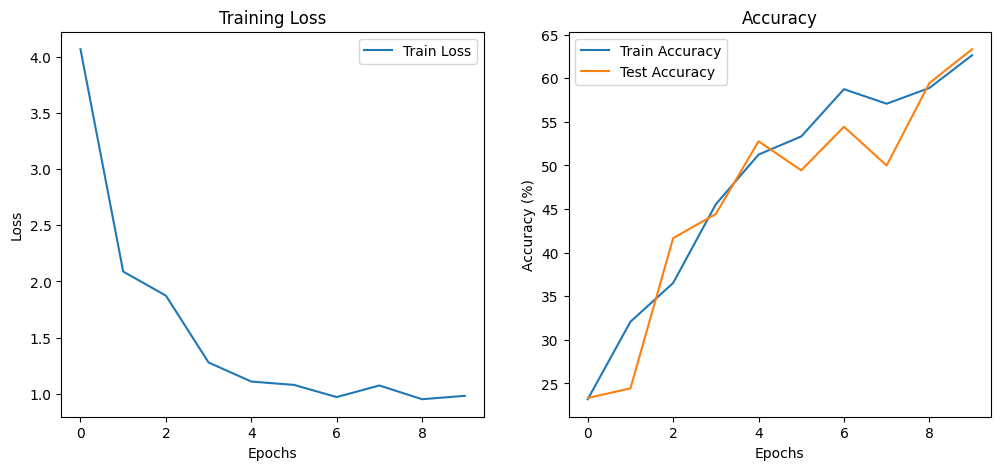

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_acc_list, label='Train Accuracy')
plt.plot(test_acc_list, label='Test Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy')
plt.legend()

plt.show()

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

model.load_state_dict(best_model_weights)

model.eval()
correct, total = 0,0
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

test_acc = 100.0 * correct/total
print(test_acc)

63.333333333333336


<Axes: >

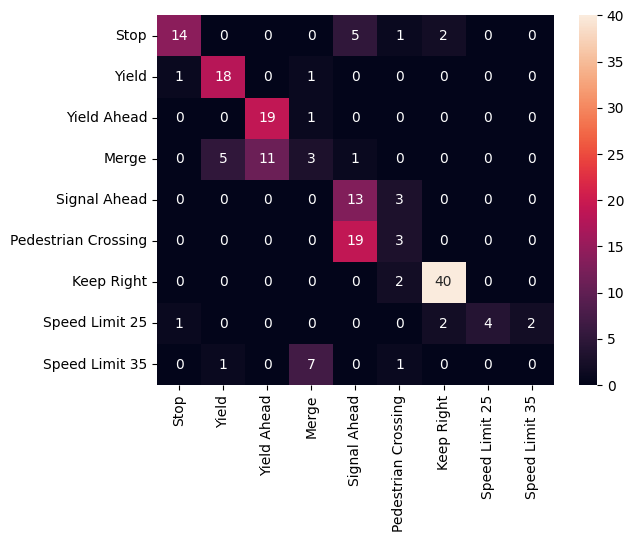

In [42]:
class_names = [
    "Stop", "Yield", "Yield Ahead", "Merge",
    "Signal Ahead", "Pedestrian Crossing",
    "Keep Right", "Speed Limit 25", "Speed Limit 35"
]
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names)